# COCO-pretrained person detectors on PIROPO Room B

**Question.** How well does an off-the-shelf, COCO-pretrained detector find people in Room B, and how much of that survives when the server only gets what a WISP could send? This is the "generic hub" reference point: no training on this room at all.

**Setup.**
* Models: torchvision Faster R-CNN with a MobileNetV3-Large backbone, at 320 px (`frcnn_mnv3_320`, fast, every 2nd frame) and at 800 px (`frcnn_mnv3`, more accurate, every 6th frame). Both are trained on COCO, which includes the person class.
* Score per frame: the highest *person* confidence among the detections (0 if there are none).
* Inputs: `rgb` = the native 704×576 colour frame; `gray` = native-resolution grayscale; `WxH` = the WISP view (grayscale 160×120, then block-averaged to W×H). The detector upsamples small inputs itself.
* Sequences: the five annotated ones. The detector never saw this room, so all of them are test data. Corrupted frames (see the exploration notebook) are excluded.

Scores come from `experiments/coco_detector_eval.py` (results in `results/coco_detectors/`). This notebook only analyses them, so it runs in seconds.

## 1. Load frames, labels and detector scores

In [1]:
import sys, re
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo

seqs = piropo.load_sequences(names=piropo.ANNOTATED + ['training_bg'])
with ThreadPoolExecutor(8) as ex:
    for s in seqs.values():
        s['X'] = np.stack(list(ex.map(piropo.load_gray, s['files'])))
        s['bad'] = piropo.flag_bad(s['X'])
BG = np.median(seqs['training_bg']['X'], axis=0)

RES_DIR = piropo.REPO / 'results' / 'coco_detectors'
R = {}   # (model, cond) -> {seq: (frame indices, scores)}
for f in sorted(RES_DIR.glob('*.npz')):
    model, cond = re.match(r'(.+)_([^_]+)_s\d+$', f.stem).groups()
    d = np.load(f)
    R[model, cond] = {n: (d[f'idx_{n}'], d[f'score_{n}']) for n in piropo.ANNOTATED if f'idx_{n}' in d}
print('available:', sorted(R))

def bytes_of(cond):
    return {'rgb': 704 * 576 * 3, 'gray': 704 * 576}.get(cond) or int(np.prod([int(v) for v in cond.split('x')]))

def gather(model, cond, names):
    # scores and labels over the given sequences, corrupted frames dropped
    sc, y = [], []
    for n in names:
        idx, s = R[model, cond][n]
        keep = ~seqs[n]['bad'][idx]
        sc.append(s[keep]); y.append(seqs[n]['label'][idx][keep])
    return np.concatenate(sc), np.concatenate(y)

available: [('frcnn_mnv3', '160x120'), ('frcnn_mnv3', 'rgb'), ('frcnn_mnv3_320', '160x120'), ('frcnn_mnv3_320', '16x12'), ('frcnn_mnv3_320', '32x24'), ('frcnn_mnv3_320', '80x60'), ('frcnn_mnv3_320', 'gray'), ('frcnn_mnv3_320', 'rgb')]


## 2. AUC per sequence

AUC is threshold-free (see the exploration notebook): 1.0 means every person frame scores above every empty frame, 0.5 means chance.

In [2]:
TEST = ['test1', 'test2', 'test3']
rows = []
for (model, cond) in sorted(R, key=lambda k: (k[0], -bytes_of(k[1]))):
    row = {'model': model, 'input': cond, 'bytes': bytes_of(cond)}
    for n in piropo.ANNOTATED:
        row[n] = piropo.auc(*gather(model, cond, [n]))
    row['all 5 pooled'] = piropo.auc(*gather(model, cond, piropo.ANNOTATED))
    rows.append(row)
auc_df = pd.DataFrame(rows).set_index(['model', 'input'])
auc_df.style.format({c: '{:.3f}' for c in piropo.ANNOTATED + ['all 5 pooled']} | {'bytes': '{:,}'}) \
      .background_gradient(cmap='RdYlGn', vmin=0.5, vmax=1.0, subset=piropo.ANNOTATED + ['all 5 pooled'])

## 3. At an operating point

A deployed hub must pick a threshold. Two choices:
* **0.5**: the usual detector default, no tuning at all.
* **tuned**: the threshold that maximises balanced accuracy on `training` + `training_seats`, applied to `test1`–`test3`. That uses a few minutes of labelled data from the room, but no training.

*Miss* = person frames called empty; *false alarm* = empty frames called person.

In [3]:
def rates(sc, y, t):
    p = sc >= t
    return dict(acc=(p == y).mean(), miss=(~p[y == 1]).mean(), false_alarm=p[y == 0].mean())

rows = []
for (model, cond) in sorted(R, key=lambda k: (k[0], -bytes_of(k[1]))):
    sc_tr, y_tr = gather(model, cond, ['training', 'training_seats'])
    cands = np.unique(np.r_[sc_tr, 0.5])
    err = [sum(rates(sc_tr, y_tr, t)[k] for k in ('miss', 'false_alarm')) for t in cands]   # 2 * (1 - balanced acc)
    t_best = cands[int(np.argmin(err))]
    sc_te, y_te = gather(model, cond, TEST)
    for tag, t in [('0.5', 0.5), ('tuned', t_best)]:
        rows.append({'model': model, 'input': cond, 'threshold': tag, 't': t, **rates(sc_te, y_te, t)})
op_df = pd.DataFrame(rows).set_index(['model', 'input', 'threshold'])
print(f'test1-3 pooled: {len(y_te)} frames per row for the last model, {100 * y_te.mean():.0f}% person')
op_df.style.format({'t': '{:.3f}', 'acc': '{:.1%}', 'miss': '{:.1%}', 'false_alarm': '{:.1%}'})

test1-3 pooled: 382 frames per row for the last model, 66% person


## 4. Generic detector vs. room-specific background, at the same bytes

The background baseline from the exploration notebook (mean |thumbnail − empty-room thumbnail|) needs no training, only one capture of the empty room. Here it is scored on exactly the same frames as the 320 px detector.

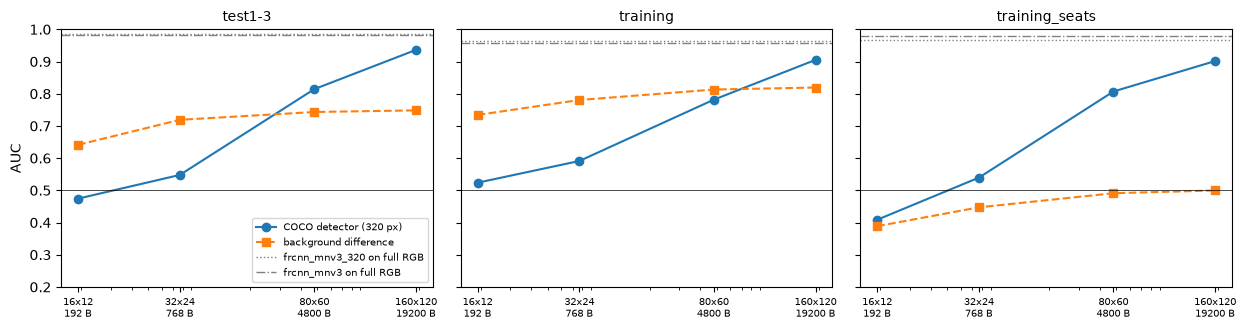

In [4]:
M = 'frcnn_mnv3_320'
small = sorted([c for (m, c) in R if m == M and 'x' in c], key=bytes_of)

def bg_score(cond, names):
    w, h = map(int, cond.split('x'))
    bg_t = piropo.thumb(BG, w, h)
    sc, y = [], []
    for n in names:
        idx = R[M, cond][n][0]
        keep = ~seqs[n]['bad'][idx]
        sc.append(np.abs(piropo.thumb(seqs[n]['X'][idx][keep], w, h) - bg_t).mean((1, 2)))
        y.append(seqs[n]['label'][idx][keep])
    return np.concatenate(sc), np.concatenate(y)

groups = {'test1-3': TEST, 'training': ['training'], 'training_seats': ['training_seats']}
fig, axes = plt.subplots(1, len(groups), figsize=(4.2 * len(groups), 3.4), sharey=True)
for ax, (g, names) in zip(axes, groups.items()):
    b = [bytes_of(c) for c in small]
    ax.plot(b, [piropo.auc(*gather(M, c, names)) for c in small], 'o-', label='COCO detector (320 px)')
    ax.plot(b, [piropo.auc(*bg_score(c, names)) for c in small], 's--', label='background difference')
    for m, c, ls in [(M, 'rgb', ':'), ('frcnn_mnv3', 'rgb', '-.')]:
        if (m, c) in R:
            ax.axhline(piropo.auc(*gather(m, c, names)), ls=ls, c='gray', lw=1, label=f'{m} on full RGB')
    ax.axhline(0.5, c='k', lw=0.5)
    ax.set_xscale('log'); ax.set_xticks(b); ax.set_xticklabels([f'{c}\n{bytes_of(c)} B' for c in small], fontsize=7)
    ax.set_title(g, fontsize=10); ax.set_ylim(0.2, 1.0)
axes[0].set_ylabel('AUC'); axes[0].legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

## 5. Where the full-resolution detector fails

The most confident false alarms and the least confident misses for `frcnn_mnv3_320` on full RGB, with the detector's person boxes (score ≥ 0.3) redrawn in red and the annotated head points in green.

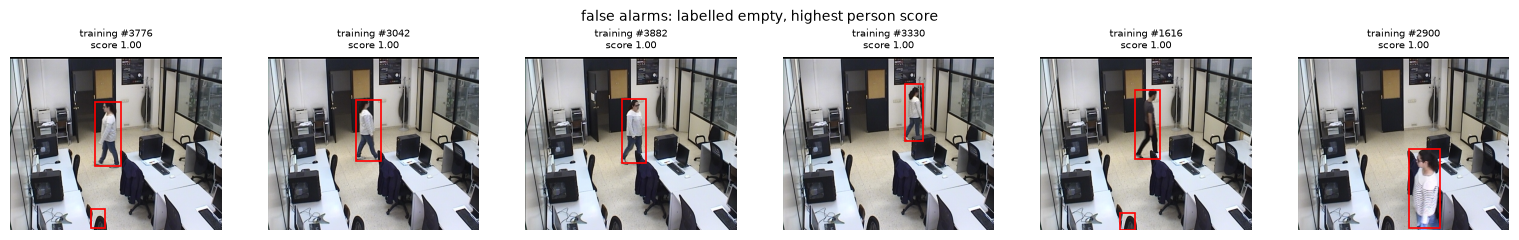

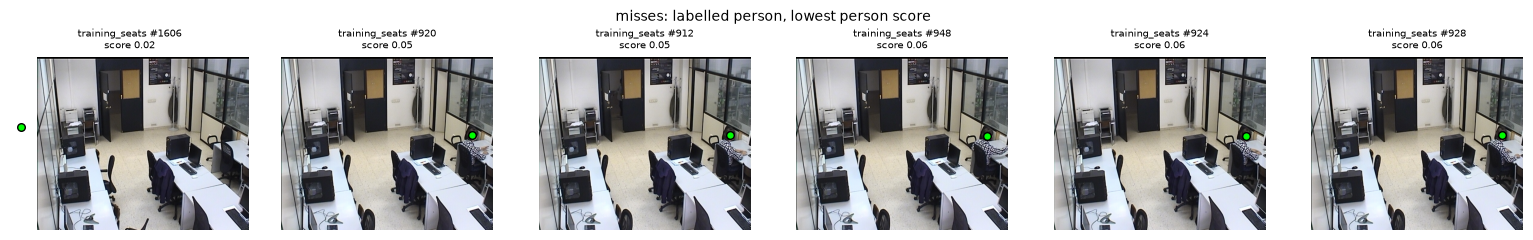

In [5]:
import torch
from torchvision.models import detection as D
det = D.fasterrcnn_mobilenet_v3_large_320_fpn(weights=D.FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT,
                                              box_score_thresh=0.3).eval()

def cases(model, cond, k=6):
    fp, fn = [], []
    for n in piropo.ANNOTATED:
        idx, s = R[model, cond][n]
        y, bad = seqs[n]['label'][idx], seqs[n]['bad'][idx]
        fp += [(sc, n, i) for sc, i, l, b in zip(s, idx, y, bad) if l == 0 and not b]
        fn += [(sc, n, i) for sc, i, l, b in zip(s, idx, y, bad) if l == 1 and not b]
    return sorted(fp, reverse=True)[:k], sorted(fn)[:k]

def show(items, title):
    fig, axes = plt.subplots(1, len(items), figsize=(2.6 * len(items), 2.4))
    for ax, (sc, n, i) in zip(axes, items):
        with Image.open(seqs[n]['files'][i]) as im:
            rgb = im.convert('RGB')
        with torch.inference_mode():
            out = det([torch.from_numpy(np.array(rgb)).permute(2, 0, 1).float() / 255])[0]
        ax.imshow(rgb)
        for (x0, y0, x1, y1), l in zip(out['boxes'].tolist(), out['labels'].tolist()):
            if l == 1:
                ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='r', lw=1.2))
        if len(seqs[n]['points'][i]):
            ax.scatter(*seqs[n]['points'][i].T, s=30, c='lime', edgecolors='k')
        ax.set_title(f'{n} #{i}\nscore {sc:.2f}', fontsize=7); ax.axis('off')
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

fp, fn = cases('frcnn_mnv3_320', 'rgb')
show(fp, 'false alarms: labelled empty, highest person score')
show(fn, 'misses: labelled person, lowest person score')

The confident "false alarms" above are people the annotation missed. How common is that? Count empty-labelled frames where the full-RGB detector is at least 90% sure there is a person (only the top cases were checked by eye, so treat these counts as *probable* label errors):

In [6]:
for n in piropo.ANNOTATED:
    idx, sc = R['frcnn_mnv3_320', 'rgb'][n]
    neg = (seqs[n]['label'][idx] == 0) & ~seqs[n]['bad'][idx]
    hi = neg & (sc >= 0.9)
    print(f'{n:<16}{neg.sum():>5} empty-labelled frames scored, {hi.sum():>3} with person score >= 0.9 ({hi.sum() / neg.sum():.0%})')

training          506 empty-labelled frames scored,  38 with person score >= 0.9 (8%)
training_seats    481 empty-labelled frames scored,   7 with person score >= 0.9 (1%)
test1              70 empty-labelled frames scored,   0 with person score >= 0.9 (0%)
test2              13 empty-labelled frames scored,   0 with person score >= 0.9 (0%)
test3              46 empty-labelled frames scored,   2 with person score >= 0.9 (4%)


## 6. Findings (first run, 2026-10-22)

1. **A generic COCO detector solves this room at full resolution, without any room-specific training.** The pooled AUC is 0.97, with 0.96–1.00 on the test sequences, and about 96% accuracy on `test1`–`test3` at the default 0.5 threshold. Grayscale costs little (AUC 0.94). The task is easy with enough pixels; the whole difficulty is the byte budget.
2. **At the WISP's native 160×120 grayscale (19.2 KB, many EPCs) it still works**: AUC 0.91 for the 320 px model and 0.93 for the 800 px model. At the default threshold the 320 px model misses 21% of person frames, mostly small or partly visible people; a threshold tuned on the training sequences brings accuracy to 90%.
3. **Below that it collapses**: AUC 0.82 at 80×60 (4.8 KB), 0.57 at 32×24 (768 B), and chance at 16×12 (192 B). Sending a thumbnail to a generic pretrained hub does not reach the EPC-sized regime. That is consistent with the Colab result (~65% at 10 B on COCO), and it is the gap that learned tag encoders and room-specific decoders have to close.
4. **Room knowledge matters most at the smallest budgets.** On `test1`–`test3`, the training-free background difference beats the COCO detector at 192 B and 768 B (AUC 0.64 and 0.72 vs. 0.47 and 0.55); the detector wins from 80×60 up. On `training_seats`, both fail at small budgets because the room layout changed (exploration notebook). That points back to a background or encoder that keeps adapting.
5. **The labels have gaps.** In `training`, 8% of the empty-labelled frames sampled get a person score ≥ 0.9, and the ones checked by eye show a clearly visible person (1% in `training_seats`; 0–4% in the test sequences). The worst misses are people barely in view: an arm at the frame edge, someone behind a monitor, a head point outside the frame. So the full-resolution numbers are a *lower bound*, and any method's measured AUC is capped by label noise. For experiments, the full-resolution detector would make a good **pseudo-labeller or teacher**: it is effectively the "full image" upper bound of the Colab notebook, available for this room.

**Caveats.** `frcnn_mnv3` (800 px) was scored on every 6th frame, so its test numbers rest on ~130 frames (`test2` on ~23), which is too few to separate it from the 320 px model. A detector is not the same as the classifier hub in the Colab notebook; a COCO-trained Visual Wake Words classifier may degrade differently at low resolution.